# Tourism Monthly — a global multi-series forecasting test

**Can a global sequential model beat CatBoost and a simple MLP on 366 related monthly series?**

This new experiment is motivated by the [Hugging Face Transformer forecasting example](https://huggingface.co/blog/time-series-transformers), which reports **MASE 1.256 for its Transformer and 1.699 for a CatBoost benchmark** on Tourism Monthly. **Those are published results, not outputs from this notebook.** We use the same public dataset, but the pipeline, architectures and validation policy here are different, so numerical agreement is not expected.

- Forecast the **final 24 months** of each series; validate on the **preceding 24 months**; train only on earlier history.
- Use 18 months of lookback for **all** models, including CatBoost. This length permits training windows even for the shortest series in this dataset (minimum 91 months); change it before running if desired.
- Train **global** models using training windows from all series. No test or validation target leaks into training.
- Predict *last-value-relative, per-series-scaled* targets. Compute each scale from the **training portion only**.
- Primary metric: **mean MASE across series**, with seasonal-naive training scale (12-month period). Also report per-series sMAPE.
- Include seasonal naive, MLP, GRU, LSTM, TCN, patch-based Transformer and two CatBoost feature configurations. The patch model here is a compact example, **not an exact reproduction of PatchTST**.

This is an additional study, not an exact reproduction of the published Transformer/CatBoost scores. All results are generated when you execute the notebook.

In [1]:
# Install if needed: %pip install numpy pandas matplotlib torch catboost
from pathlib import Path
import urllib.request, zipfile, math, json, time, os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from catboost import CatBoostRegressor

SEED = 42
LOOKBACK = 18
HORIZON = 24
VAL_MONTHS = 24
TEST_MONTHS = 24
MAX_EPOCHS = 50
PATIENCE = 8
BATCH_SIZE = 256
LEARNING_RATE = 0.001
CATBOOST_ITERATIONS = 400
CATBOOST_PATIENCE = 60
MAX_TRAIN_WINDOWS = 30000       # same deterministic subset of examples for all models
RUN_ENGINEERED_CATBOOST = True
NEURAL_MODELS = ['MLP','GRU','LSTM','TCN','Patch Transformer']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
torch.set_num_threads(min(4, os.cpu_count() or 1))
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
print('Device:',DEVICE, '| torch',torch.__version__)

Device: mps | torch 2.12.0


In [3]:
# Source: https://zenodo.org/records/4656096 (Monash Tourism Monthly 366 series)
DATA_URL='https://zenodo.org/api/records/4656096/files/tourism_monthly_dataset.zip/content'
cache_dir=Path('benchmark_data');cache_dir.mkdir(exist_ok=True)
archive_path=cache_dir/'tourism_monthly_dataset.zip'
if not archive_path.exists():
    print('Downloading',DATA_URL)
    try:urllib.request.urlretrieve(DATA_URL, archive_path)
    except Exception as e:raise RuntimeError('Download failed. Download tourism_monthly_dataset.zip from https://zenodo.org/records/4656096 and place it in benchmark_data/.') from e

def parse_tsf(contents):
    # Change 'utf-8-sig' to 'latin-1' to handle non-UTF-8 bytes in the file
    lines = contents.decode("latin-1").splitlines()
    attributes = []
    in_data = False
    series = []
    for line in lines:
      line = line.strip()
      if not line or line.startswith("#"):
        continue
      if line.startswith("@attribute"):
        attributes.append(line.split()[1])
        continue
      if line.lower() == "@data":
        in_data = True
        continue
      if line.startswith("@"):
        continue
      if not in_data:
        continue
      fields = line.split(":")
      if len(fields) != len(attributes) + 1:
        raise ValueError(
            f"Unexpected TSF row columns: expected {len(attributes) + 1}, got"
            f" {len(fields)}"
        )
      attrs = dict(zip(attributes, fields[:-1]))
      nums = np.array(
          [
              float(v) if v.strip() not in ("?", "NaN") else np.nan
              for v in fields[-1].split(",")
          ],
          dtype=np.float64,
      )
      if not np.all(np.isfinite(nums)):
        raise ValueError(
            "Unexpected missing value: review imputation before continuing"
        )
      if len(nums) < LOOKBACK + VAL_MONTHS + TEST_MONTHS:
        continue
      key = str(
          attrs.get("series_name", attrs.get("series_id", len(series)))
      )
      dt = str(attrs.get("start_timestamp", ""))
      try:
        start_month = int(pd.Period(dt[:7], freq="M").month)
      except Exception as ex:
        raise ValueError(f"Could not parse start_timestamp for {key}: {dt!r}") from ex
      series.append({"name": key, "values": nums, "start_month": start_month})
    return series
with zipfile.ZipFile(archive_path) as z:
    paths=[p for p in z.namelist() if p.lower().endswith('.tsf')]
    if not paths:raise ValueError(f'TSF file not found in archive: {z.namelist()}')
    series=parse_tsf(z.read(paths[0]))
if len(series)<3:raise ValueError(f'Only {len(series)} series loaded')
print('Number of series:',len(series),'min/median/max length:',
      min(len(s['values']) for s in series),int(np.median([len(s['values']) for s in series])),max(len(s['values']) for s in series))
print('First series',series[0]['name'], 'months',len(series[0]['values']))

Number of series: 366 min/median/max length: 91 330 333
First series T1 months 187


In [4]:
# Forecast origins: train t+24 <= n-48; validation t=n-48; test t=n-24.
# No target for a training example is permitted to touch the two held-out blocks.
# Month-of-year is known in advance; future target data and future observations are not inputs.

def month_features(start_month,absolute_month):
    m=(start_month-1+np.asarray(absolute_month))%12
    return np.stack((np.sin(2*np.pi*m/12),np.cos(2*np.pi*m/12)),axis=-1).astype(np.float32)

for s in series:
    v=s['values'];n=len(v)
    cutoff=n-VAL_MONTHS-TEST_MONTHS
    s['scale']=max(float(np.mean(np.abs(v[:cutoff]))),1e-4)
    s['mase_scale']=max(float(np.mean(np.abs(v[12:cutoff]-v[:cutoff-12]))),1e-4)
    s['train_end']=cutoff

# X: history of relative scaled values + past seasonal phase. C: future known phase.
# Predictions and ground truth are both last-observation-relative and divided by series training scale.
def sample(s,t):
    v=s['values'];scale=s['scale'];anchor=float(v[t-1]);
    history=(v[t-LOOKBACK:t]-anchor)/scale
    month=month_features(s['start_month'],np.arange(t-LOOKBACK,t))
    x=np.column_stack((history,month)).astype(np.float32)
    c=month_features(s['start_month'],np.arange(t,t+HORIZON)).reshape(-1)
    y=((v[t:t+HORIZON]-anchor)/scale).astype(np.float32)
    return x,c,y,anchor

samples={p:[] for p in ('Train','Validation','Test')}
for sid,s in enumerate(series):
    n=len(s['values']);tr_end=s['train_end']
    for t in range(LOOKBACK,tr_end-HORIZON+1):samples['Train'].append((sid,t))
    samples['Validation'].append((sid,n-VAL_MONTHS-TEST_MONTHS))
    samples['Test'].append((sid,n-TEST_MONTHS))
assert len(samples['Train'])>0
if len(samples['Train'])>MAX_TRAIN_WINDOWS:
    idx=np.linspace(0,len(samples['Train'])-1,MAX_TRAIN_WINDOWS,dtype=int)
    samples['Train']=[samples['Train'][j] for j in idx]
for part,items in samples.items():
    for sid,t in items:
        n=len(series[sid]['values'])
        if part=='Train':assert t+HORIZON<=n-VAL_MONTHS-TEST_MONTHS
        if part=='Validation':assert t==n-VAL_MONTHS-TEST_MONTHS
        if part=='Test':assert t==n-TEST_MONTHS

def pack(part):
    xs=[];cs=[];ys=[];anchors=[];sids=[]
    for sid,t in samples[part]:
        x,c,y,a=sample(series[sid],t)
        xs.append(x);cs.append(c);ys.append(y);anchors.append(a);sids.append(sid)
    return np.stack(xs),np.stack(cs),np.stack(ys),np.asarray(anchors),np.asarray(sids)
packed={part:pack(part) for part in samples}
for part,(x,c,y,a,sid) in packed.items():
    print(part, 'examples:',len(y),'X',x.shape,'future_calendar',c.shape,'y',y.shape)
    assert np.all(np.isfinite(x)) and np.all(np.isfinite(c)) and np.all(np.isfinite(y))

# Future leakage test: no future change can alter sample inputs.
s=series[0];t=s['train_end'];x0,c0,_,_=sample(s,t)
alt=dict(s);alt['values']=s['values'].copy();alt['values'][t:]+=1e7
x1,c1,_,_=sample(alt,t)
assert np.array_equal(x0,x1) and np.array_equal(c0,c1)
print('Passed forecast-origin leakage assertions.')

Train examples: 30000 X (30000, 18, 3) future_calendar (30000, 48) y (30000, 24)
Validation examples: 366 X (366, 18, 3) future_calendar (366, 48) y (366, 24)
Test examples: 366 X (366, 18, 3) future_calendar (366, 48) y (366, 24)
Passed forecast-origin leakage assertions.


In [5]:
def metrics(pred,part):
    x,c,y,a,sids=packed[part]
    # pred is on the normalized relative-target scale.
    errors=[];smape=[];mae=[]
    for k,sid in enumerate(sids):
        s=series[int(sid)]
        pp=(np.asarray(pred[k])*s['scale'])+a[k]
        actual=(y[k]*s['scale'])+a[k]
        per_point_err=np.abs(pp-actual)
        errors.append(np.mean(per_point_err)/s['mase_scale'])
        smape.append(np.mean(2*per_point_err/np.maximum(np.abs(pp)+np.abs(actual),1e-6)))
        mae.append(np.mean(per_point_err))
    return dict(mase=float(np.mean(errors)),smape=float(np.mean(smape)*100),mae=float(np.mean(mae)))

class MLP(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(LOOKBACK*3+2*HORIZON,256),nn.ReLU(),nn.Dropout(.1),nn.Linear(256,128),nn.ReLU(),nn.Linear(128,HORIZON))
    def forward(self,x,c):return self.net(torch.cat([x.flatten(1),c],dim=1))
class RNN(nn.Module):
    def __init__(self,kind):
        super().__init__();self.rnn=(nn.GRU if kind=='GRU' else nn.LSTM)(3,64,batch_first=True);self.head=nn.Linear(64+2*HORIZON,HORIZON)
    def forward(self,x,c):return self.head(torch.cat([self.rnn(x)[0][:,-1,:],c],dim=1))
class ResidualTCN(nn.Module):
    def __init__(self):
        super().__init__();self.layers=nn.ModuleList([nn.Conv1d(3 if i==0 else 64,64,3,dilation=2**i) for i in range(4)]);self.head=nn.Linear(64+2*HORIZON,HORIZON)
    def forward(self,x,c):
        z=x.transpose(1,2)
        for i,layer in enumerate(self.layers):
            d=2**i;z=F.relu(layer(F.pad(z,(2*d,0))))
        return self.head(torch.cat([z[:,:,-1],c],dim=1))
class PatchTransformer(nn.Module):
    def __init__(self):
        super().__init__();self.patch=nn.Linear(6*3,64);self.pos=nn.Parameter(torch.zeros(1,5,64));
        enc=nn.TransformerEncoderLayer(d_model=64,nhead=4,dim_feedforward=128,dropout=.1,batch_first=True)
        self.encoder=nn.TransformerEncoder(enc,num_layers=2,enable_nested_tensor=False)
        self.head=nn.Sequential(nn.Linear(5*64+2*HORIZON,128),nn.ReLU(),nn.Linear(128,HORIZON))
    def forward(self,x,c):
        # 18-month history -> 5 overlapping six-month patches, stride 3.
        p=x.unfold(dimension=1,size=6,step=3).permute(0,1,3,2).reshape(x.size(0),5,18)
        z=self.encoder(self.patch(p)+self.pos).flatten(1)
        return self.head(torch.cat([z,c],dim=1))
FACTORIES={'MLP':MLP,'GRU':lambda:RNN('GRU'),'LSTM':lambda:RNN('LSTM'),'TCN':ResidualTCN,'Patch Transformer':PatchTransformer}

def loader(part,shuffle=False):
    x,c,y,*_=packed[part]
    return DataLoader(TensorDataset(torch.from_numpy(x),torch.from_numpy(c),torch.from_numpy(y)),batch_size=BATCH_SIZE,shuffle=shuffle)

@torch.no_grad()
def infer(model,part):
    model.eval();parts=[]
    for x,c,_ in loader(part):parts.append(model(x.to(DEVICE),c.to(DEVICE)).cpu().numpy())
    return np.concatenate(parts,axis=0)

def train_model(name):
    torch.manual_seed(SEED)
    model=FACTORIES[name]().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=1e-4)
    best=float('inf');best_state=None;best_epoch=None;stale=0
    for epoch in range(1,MAX_EPOCHS+1):
        model.train()
        for x,c,y in loader('Train',shuffle=True):
            opt.zero_grad(set_to_none=True)
            loss=F.mse_loss(model(x.to(DEVICE),c.to(DEVICE)),y.to(DEVICE))
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);opt.step()
        pred=infer(model,'Validation');yv=packed['Validation'][2]
        val_mse=float(np.mean((pred-yv)**2))
        if val_mse<best-1e-6:
            best=val_mse;best_epoch=epoch;stale=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            stale+=1
            if stale>=PATIENCE:break
    model.load_state_dict(best_state)
    return model,best_epoch


In [6]:
# Strong seasonal-naive comparator: repeat the same calendar months a year ago.
def seasonal_naive(part):
    out=[]
    for sid,t in samples[part]:
        s=series[sid];v=s['values'];a=v[t-1]
        seasonal=v[t-12:t] # known past 12 months
        forecast=np.tile(seasonal,int(math.ceil(HORIZON/12)))[:HORIZON]
        out.append((forecast-a)/s['scale'])
    return np.stack(out)

rows=[];predictions={}
for name in NEURAL_MODELS:
    start=time.perf_counter()
    model,ep=train_model(name)
    pred=infer(model,'Test');pv=infer(model,'Validation')
    predictions[name]=pred
    row={'model':name,'family':'Neural','best_epoch':ep,'train_seconds':round(time.perf_counter()-start,2),
         'val_mase':metrics(pv,'Validation')['mase'],**metrics(pred,'Test')}
    rows.append(row)
    print(f'{name:18s} test MASE={row["mase"]:.4f} val MASE={row["val_mase"]:.4f} epoch={ep}',flush=True)

naive_pred=seasonal_naive('Test');naive_val=seasonal_naive('Validation')
predictions['Seasonal naive']=naive_pred
rows.append({'model':'Seasonal naive','family':'Naive','best_epoch':None,'train_seconds':0.0,
             'val_mase':metrics(naive_val,'Validation')['mase'],**metrics(naive_pred,'Test')})

MLP                test MASE=1.6752 val MASE=1.8220 epoch=4
GRU                test MASE=2.1149 val MASE=2.1902 epoch=19
LSTM               test MASE=2.0349 val MASE=2.0914 epoch=42
TCN                test MASE=1.7184 val MASE=1.9035 epoch=5
Patch Transformer  test MASE=1.7583 val MASE=1.8865 epoch=11


In [7]:
# The SAME history and known future calendar are given to raw-lag CatBoost.
def flat(part,engineered=False):
    x,c,*_=packed[part]
    a=np.concatenate([x.reshape(len(x),-1),c],axis=1)
    if engineered:
        v=x[:,:,0]
        extra=np.column_stack([
          v.mean(1),v.std(1),v.min(1),v.max(1),
          v[:,-3:].mean(1),v[:,-6:].mean(1),v[:,-12:].mean(1),
          v[:,-1]-v[:,-12],v[:,-1]-v[:,0],
          v[:,-6:].std(1),v[:,-12:].std(1),
          v[:,-12]-v[:,0]
        ])
        a=np.concatenate((a,extra),axis=1)
    return a.astype(np.float32)

for engineered in ([False,True] if RUN_ENGINEERED_CATBOOST else [False]):
    name='CatBoost (engineered)' if engineered else 'CatBoost (raw lags)'
    tic=time.perf_counter()
    model=CatBoostRegressor(iterations=CATBOOST_ITERATIONS,depth=6,learning_rate=.05,loss_function='MultiRMSE',
                            l2_leaf_reg=3,random_seed=SEED,task_type='CPU',thread_count=4,allow_writing_files=False)
    model.fit(flat('Train',engineered),packed['Train'][2],
              eval_set=(flat('Validation',engineered),packed['Validation'][2]),
              early_stopping_rounds=CATBOOST_PATIENCE,use_best_model=True,verbose=False)
    pred=model.predict(flat('Test',engineered));pv=model.predict(flat('Validation',engineered))
    predictions[name]=pred
    row={'model':name,'family':'Tree','best_epoch':model.tree_count_,'train_seconds':round(time.perf_counter()-tic,2),
         'val_mase':metrics(pv,'Validation')['mase'],**metrics(pred,'Test')}
    rows.append(row)
    print(f'{name:23s} test MASE={row["mase"]:.4f} val MASE={row["val_mase"]:.4f} trees={model.tree_count_}',flush=True)

CatBoost (raw lags)     test MASE=1.8742 val MASE=1.8983 trees=396
CatBoost (engineered)   test MASE=1.9464 val MASE=1.9398 trees=322


,model,family,best_epoch,train_seconds,val_mase,mase,smape,mae
0,MLP,Neural,4.0,5.24,1.8220,1.6752,20.0539,1985.0278
1,TCN,Neural,5.0,7.14,1.9035,1.7184,20.1301,1953.3707
2,Patch Transformer,Neural,11.0,30.97,1.8865,1.7583,20.4661,1960.4046
3,Seasonal naive,Naive,NaN,0.00,1.9951,1.7805,21.6699,1980.2072
4,CatBoost (raw lags),Tree,396.0,52.81,1.8983,1.8742,20.8416,2166.0920
5,CatBoost (engineered),Tree,322.0,60.41,1.9398,1.9464,21.5404,2288.9007
6,LSTM,Neural,42.0,20.82,2.0914,2.0349,22.8597,2375.5032
7,GRU,Neural,19.0,24.16,2.1902,2.1149,23.3159,2593.1994


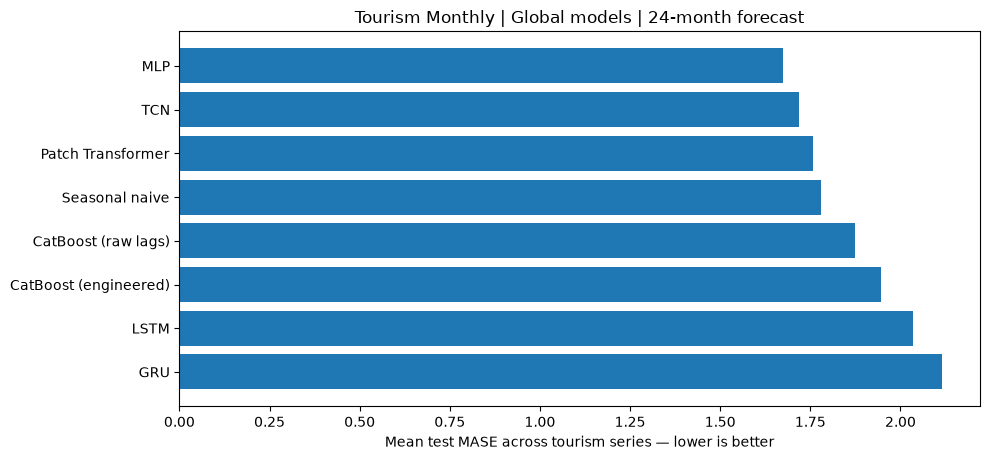

Validation-selected model: MLP | its held-out test MASE: 1.6752
Post-hoc test ranking should NOT be used to tune or select datasets.
Saved outputs: /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/forecast_challenge_outputs/tourism_monthly


In [8]:
# Only executed results (never embedded claims copied from papers).
out=Path('forecast_challenge_outputs/tourism_monthly');out.mkdir(parents=True,exist_ok=True)
summary=pd.DataFrame(rows).sort_values('mase').reset_index(drop=True)
display(summary.round(4))
summary.to_csv(out/'comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4.7))
s=summary.iloc[::-1]
ax.barh(s.model,s.mase)
ax.set(xlabel='Mean test MASE across tourism series — lower is better',title='Tourism Monthly | Global models | 24-month forecast')
fig.tight_layout();fig.savefig(out/'mase_ranking.png',dpi=150);plt.show()
selected=summary.query('family!="Naive"').sort_values('val_mase').iloc[0]
print('Validation-selected model:',selected.model,'| its held-out test MASE:',round(selected.mase,4))
print('Post-hoc test ranking should NOT be used to tune or select datasets.')
np.savez_compressed(out/'predictions.npz',**{k.replace(' ','_').replace('(','').replace(')',''):v for k,v in predictions.items()})
config={'dataset':'tourism_monthly','source':DATA_URL,'num_series':len(series),'seed':SEED,
        'lookback':LOOKBACK,'horizon':HORIZON,'validation_block_months':VAL_MONTHS,
        'test_block_months':TEST_MONTHS,'max_epochs':MAX_EPOCHS,'patience':PATIENCE,
        'catboost_iterations':CATBOOST_ITERATIONS,'catboost_patience':CATBOOST_PATIENCE,
        'train_windows':len(samples['Train']),'neural_models':NEURAL_MODELS,
        'notes':'Separate global panel experiment, not identical to published Transformer/CatBoost setup or single-series suite.'}
(out/'run_info.json').write_text(json.dumps(config,indent=2),encoding='utf8')
print('Saved outputs:',out.resolve())

## Interpreting the experiment

A neural win here would be on **the same held-out series, same input history, same calendar features, and same training examples** as CatBoost, under the fixed budgets above. It would **not** prove PatchTST beats CatBoost in general. A CatBoost win would not invalidate published Transformer results either, because architectures, lookbacks, splits, loss functions, and tuning differ.

**Different from the Hugging Face blog:** our Patch Transformer is not the same model; our training/validation/test windows and normalization are independent choices; our reported results are therefore not a reproduction of the 1.256/1.699 MASE comparison. All models here use a globally trained direct 24-step predictor and training-only per-series scale. The two CatBoost variants are raw lags and explicitly additional *causal* features. For statistical confidence use multiple seeds, rolling-origin folds and paired block/bootstrap uncertainty over series.

Data: [Monash Tourism Monthly](https://zenodo.org/records/4656096), 366 series; authors Godahewa et al., CC BY 4.0. Published comparison: [Hugging Face Time Series Transformers](https://huggingface.co/blog/time-series-transformers).